In [3]:
import os
import json
import zipfile
import hashlib
import random
import shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from google.colab import files

print("=" * 65)
print("DATASET AUDIT AND VISUALISATION")
print("=" * 65)

DATASET AUDIT AND VISUALISATION


In [5]:
print("\nUpload your COCO dataset ZIP file.")

uploaded = files.upload()

zip_files = [
    f for f in uploaded.keys()
    if f.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload a ZIP file.")

zip_path = zip_files[0]

extract_path = "/content/traffic_dataset"

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\nDataset extracted successfully!")


Upload your COCO dataset ZIP file.


Saving Indian_Traffic_Sample_COCO.zip to Indian_Traffic_Sample_COCO.zip

Dataset extracted successfully!


In [6]:
json_files = []

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith(".json"):
            json_files.append(os.path.join(root, filename))

if not json_files:
    raise FileNotFoundError("No JSON annotation file found.")

preferred = [
    path for path in json_files
    if "instances" in os.path.basename(path).lower()
]

annotation_path = preferred[0] if preferred else json_files[0]

with open(annotation_path, "r") as f:
    coco = json.load(f)

images = coco.get("images", [])
annotations = coco.get("annotations", [])
categories = coco.get("categories", [])

if not images or not categories:
    raise ValueError("Invalid COCO dataset structure.")

category_map = {
    category["id"]: category["name"]
    for category in categories
}

image_map = {
    image["id"]: image
    for image in images
}

print("\nDataset loaded successfully!")
print("Total images:", len(images))
print("Total annotations:", len(annotations))
print("Total categories:", len(categories))


Dataset loaded successfully!
Total images: 1
Total annotations: 6
Total categories: 5


In [7]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_paths = {}

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:

        if filename.lower().endswith(image_extensions):

            full_path = os.path.join(root, filename)

            relative_path = os.path.relpath(
                full_path, extract_path
            ).replace("\\", "/")

            image_paths[relative_path] = full_path


def find_image(file_name):

    normalized = str(file_name).replace("\\", "/").lstrip("./")

    if normalized in image_paths:
        return image_paths[normalized]

    basename = os.path.basename(normalized)

    matches = [
        path for path in image_paths.values()
        if os.path.basename(path) == basename
    ]

    return matches[0] if matches else None

In [8]:
print("\n" + "=" * 65)
print("STEP 1: CLASS DISTRIBUTION")
print("=" * 65)

class_counts = Counter()
class_images = {
    name: set() for name in category_map.values()
}

for annotation in annotations:

    category_id = annotation.get("category_id")
    image_id = annotation.get("image_id")

    if category_id in category_map:

        class_name = category_map[category_id]

        class_counts[class_name] += 1
        class_images[class_name].add(image_id)

class_df = pd.DataFrame({
    "Class": list(category_map.values()),

    "Annotation_Count": [
        class_counts[name]
        for name in category_map.values()
    ],

    "Images_Containing_Class": [
        len(class_images[name])
        for name in category_map.values()
    ]
})

class_df = class_df.sort_values(
    by="Annotation_Count",
    ascending=False
)

print("\nClass Distribution:")
display(class_df)

print("\nTotal object categories:", len(categories))
print("Total annotated objects:", len(annotations))


STEP 1: CLASS DISTRIBUTION

Class Distribution:


,Class,Annotation_Count,Images_Containing_Class
4,person,2,1
0,car,1,1
1,motorcycle,1,1
2,bus,1,1
3,auto-rickshaw,1,1



Total object categories: 5
Total annotated objects: 6



STEP 2: IMAGE QUALITY AUDIT

Image Quality Results:


,Image_ID,File_Name,Status,Width,Height,Brightness,Blur_Score,Duplicate
0,1,images/indian_traffic_sample_001.png,Good,1536,1024,114.2,560.64,False



Image Quality Summary:
Total images: 1
Missing images: 0
Corrupted images: 0
Duplicate images: 0
Low-resolution images: 0
Possibly blurry images: 0


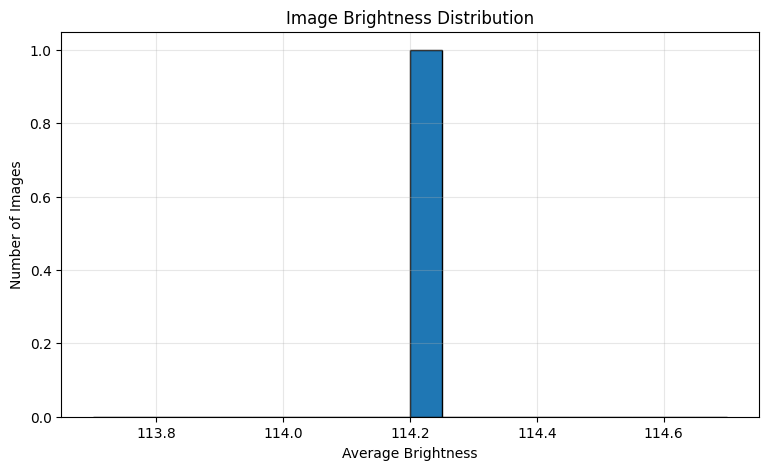

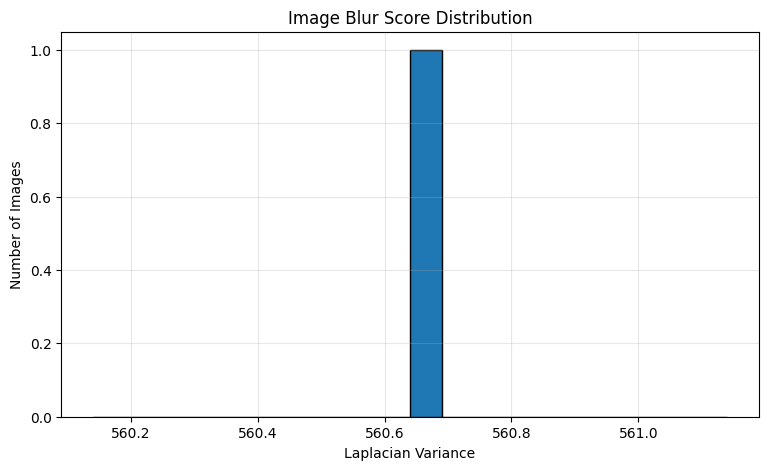

In [9]:
print("\n" + "=" * 65)
print("STEP 2: IMAGE QUALITY AUDIT")
print("=" * 65)

quality_results = []
hashes = {}

for index, image_info in enumerate(images):

    file_name = image_info.get("file_name", "")
    image_id = image_info.get("id")

    image_path = find_image(file_name)

    if image_path is None:

        quality_results.append({
            "Image_ID": image_id,
            "File_Name": file_name,
            "Status": "Missing",
            "Width": None,
            "Height": None,
            "Brightness": None,
            "Blur_Score": None,
            "Duplicate": None
        })

        continue

    img = cv2.imread(image_path)

    if img is None:

        quality_results.append({
            "Image_ID": image_id,
            "File_Name": file_name,
            "Status": "Corrupted",
            "Width": None,
            "Height": None,
            "Brightness": None,
            "Blur_Score": None,
            "Duplicate": None
        })

        continue

    height, width = img.shape[:2]

    gray = cv2.cvtColor(
        img, cv2.COLOR_BGR2GRAY
    )

    brightness = float(np.mean(gray))

    blur_score = float(
        cv2.Laplacian(gray, cv2.CV_64F).var()
    )

    with open(image_path, "rb") as f:
        image_hash = hashlib.md5(f.read()).hexdigest()

    duplicate = image_hash in hashes
    hashes[image_hash] = True

    issues = []

    if width < 300 or height < 200:
        issues.append("Low resolution")

    if brightness < 40:
        issues.append("Too dark")

    elif brightness > 220:
        issues.append("Too bright")

    if blur_score < 100:
        issues.append("Possibly blurry")

    if duplicate:
        issues.append("Duplicate")

    status = ", ".join(issues) if issues else "Good"

    quality_results.append({
        "Image_ID": image_id,
        "File_Name": file_name,
        "Status": status,
        "Width": width,
        "Height": height,
        "Brightness": round(brightness, 2),
        "Blur_Score": round(blur_score, 2),
        "Duplicate": duplicate
    })

    if (index + 1) % 100 == 0:
        print(f"Checked {index + 1}/{len(images)} images")


quality_df = pd.DataFrame(quality_results)

print("\nImage Quality Results:")
display(quality_df)

print("\nImage Quality Summary:")

print("Total images:", len(quality_df))

print(
    "Missing images:",
    (quality_df["Status"] == "Missing").sum()
)

print(
    "Corrupted images:",
    (quality_df["Status"] == "Corrupted").sum()
)

print(
    "Duplicate images:",
    quality_df["Duplicate"].eq(True).sum()
)

print(
    "Low-resolution images:",
    quality_df["Status"].str.contains(
        "Low resolution", na=False
    ).sum()
)

print(
    "Possibly blurry images:",
    quality_df["Status"].str.contains(
        "Possibly blurry", na=False
    ).sum()
)


# Brightness distribution
valid_quality = quality_df.dropna(
    subset=["Brightness"]
)

if not valid_quality.empty:

    plt.figure(figsize=(9, 5))

    plt.hist(
        valid_quality["Brightness"],
        bins=20,
        edgecolor="black"
    )

    plt.title("Image Brightness Distribution")
    plt.xlabel("Average Brightness")
    plt.ylabel("Number of Images")
    plt.grid(alpha=0.3)
    plt.show()


# Blur score distribution
valid_blur = quality_df.dropna(
    subset=["Blur_Score"]
)

if not valid_blur.empty:

    plt.figure(figsize=(9, 5))

    plt.hist(
        valid_blur["Blur_Score"],
        bins=20,
        edgecolor="black"
    )

    plt.title("Image Blur Score Distribution")
    plt.xlabel("Laplacian Variance")
    plt.ylabel("Number of Images")
    plt.grid(alpha=0.3)
    plt.show()

In [10]:
print("\n" + "=" * 65)
print("STEP 3: ANNOTATION VALIDATION")
print("=" * 65)

annotation_issues = []
valid_annotation_count = 0

for annotation in annotations:

    annotation_id = annotation.get("id")
    image_id = annotation.get("image_id")
    category_id = annotation.get("category_id")
    bbox = annotation.get("bbox")

    issues = []

    if image_id not in image_map:
        issues.append("Unknown image ID")

    if category_id not in category_map:
        issues.append("Unknown category ID")

    if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:

        issues.append("Invalid bounding box format")

    else:

        try:

            x, y, w, h = map(float, bbox)

            if not np.all(np.isfinite([x, y, w, h])):
                issues.append("Non-finite values")

            elif w <= 0 or h <= 0:
                issues.append("Invalid width or height")

            elif x < 0 or y < 0:
                issues.append("Negative coordinates")

            elif image_id in image_map:

                img_width = image_map[image_id].get("width")
                img_height = image_map[image_id].get("height")

                if img_width is not None and img_height is not None:

                    if x + w > img_width or y + h > img_height:
                        issues.append("Bounding box outside image")

        except (ValueError, TypeError):
            issues.append("Non-numeric coordinates")

    if issues:

        annotation_issues.append({
            "Annotation_ID": annotation_id,
            "Image_ID": image_id,
            "Category_ID": category_id,
            "Issues": "; ".join(issues)
        })

    else:
        valid_annotation_count += 1


annotation_issues_df = pd.DataFrame(annotation_issues)

print("Total annotations:", len(annotations))
print("Valid annotations:", valid_annotation_count)
print("Invalid annotations:", len(annotation_issues_df))

if not annotation_issues_df.empty:
    display(annotation_issues_df)
else:
    print("No annotation errors detected!")


STEP 3: ANNOTATION VALIDATION
Total annotations: 6
Valid annotations: 6
Invalid annotations: 0
No annotation errors detected!



STEP 4: ANNOTATION VISUALISATION


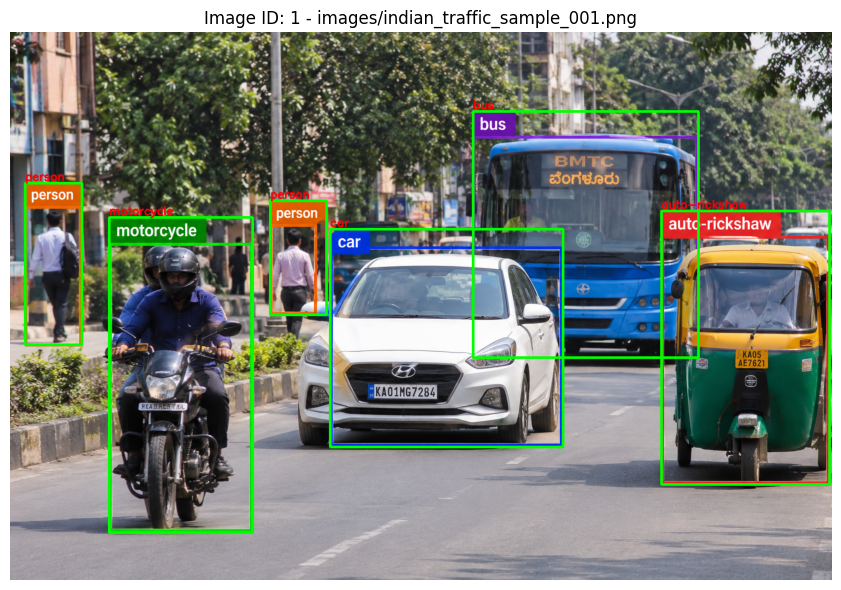

In [11]:
print("\n" + "=" * 65)
print("STEP 4: ANNOTATION VISUALISATION")
print("=" * 65)

annotations_by_image = {}

for annotation in annotations:

    image_id = annotation.get("image_id")

    annotations_by_image.setdefault(
        image_id, []
    ).append(annotation)


sample_images = []

for image_info in images:

    image_id = image_info["id"]

    if image_id in annotations_by_image:

        path = find_image(
            image_info.get("file_name", "")
        )

        if path and os.path.exists(path):
            sample_images.append(image_info)


if not sample_images:

    print("No annotated images available.")

else:

    random.seed(42)

    selected_images = random.sample(
        sample_images,
        min(5, len(sample_images))
    )

    fig, axes = plt.subplots(
        len(selected_images),
        1,
        figsize=(14, 6 * len(selected_images))
    )

    if len(selected_images) == 1:
        axes = [axes]

    for ax, image_info in zip(axes, selected_images):

        image_id = image_info["id"]

        image_path = find_image(
            image_info.get("file_name", "")
        )

        img = cv2.imread(image_path)

        img = cv2.cvtColor(
            img, cv2.COLOR_BGR2RGB
        )

        for annotation in annotations_by_image.get(image_id, []):

            bbox = annotation.get("bbox")

            if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
                continue

            try:

                x, y, w, h = map(float, bbox)

                if not np.all(np.isfinite([x, y, w, h])):
                    continue

                if w <= 0 or h <= 0:
                    continue

                category_id = annotation.get("category_id")

                label = category_map.get(
                    category_id, "Unknown"
                )

                x1 = int(max(0, x))
                y1 = int(max(0, y))

                x2 = int(min(img.shape[1], x + w))
                y2 = int(min(img.shape[0], y + h))

                if x2 <= x1 or y2 <= y1:
                    continue

                cv2.rectangle(
                    img,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    3
                )

                cv2.putText(
                    img,
                    label,
                    (x1, max(20, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (255, 0, 0),
                    2
                )

            except (ValueError, TypeError):
                continue

        ax.imshow(img)

        ax.set_title(
            f"Image ID: {image_id} - "
            f"{image_info.get('file_name', '')}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [12]:
print("\n" + "=" * 65)
print("FINAL DATASET AUDIT REPORT")
print("=" * 65)

total_images = len(images)
total_annotations = len(annotations)

missing_count = (
    quality_df["Status"] == "Missing"
).sum()

corrupted_count = (
    quality_df["Status"] == "Corrupted"
).sum()

duplicate_count = (
    quality_df["Duplicate"].eq(True)
).sum()

print("\nDATASET SUMMARY")

print("Total Images:", total_images)
print("Total Categories:", len(categories))
print("Total Annotations:", total_annotations)

print("\nIMAGE QUALITY")

print("Missing:", missing_count)
print("Corrupted:", corrupted_count)
print("Duplicates:", duplicate_count)

print("\nANNOTATION QUALITY")

print("Valid:", valid_annotation_count)
print("Invalid:", len(annotation_issues_df))

print("\nCLASS DISTRIBUTION")

print(class_df.to_string(index=False))

print("\nDataset audit completed!")



FINAL DATASET AUDIT REPORT

DATASET SUMMARY
Total Images: 1
Total Categories: 5
Total Annotations: 6

IMAGE QUALITY
Missing: 0
Corrupted: 0
Duplicates: 0

ANNOTATION QUALITY
Valid: 6
Invalid: 0

CLASS DISTRIBUTION
        Class  Annotation_Count  Images_Containing_Class
       person                 2                        1
          car                 1                        1
   motorcycle                 1                        1
          bus                 1                        1
auto-rickshaw                 1                        1

Dataset audit completed!


In [13]:
output_folder = "/content/dataset_audit_results"

os.makedirs(output_folder, exist_ok=True)

class_df.to_csv(
    os.path.join(output_folder, "class_distribution.csv"),
    index=False
)

quality_df.to_csv(
    os.path.join(output_folder, "image_quality_report.csv"),
    index=False
)

annotation_issues_df.to_csv(
    os.path.join(output_folder, "annotation_errors.csv"),
    index=False
)

with open(
    os.path.join(output_folder, "final_audit_report.txt"),
    "w"
) as f:

    f.write("DATASET AUDIT REPORT\n")
    f.write("=" * 40 + "\n")

    f.write(f"Total Images: {total_images}\n")
    f.write(f"Total Categories: {len(categories)}\n")
    f.write(f"Total Annotations: {total_annotations}\n")

    f.write(f"Missing Images: {missing_count}\n")
    f.write(f"Corrupted Images: {corrupted_count}\n")
    f.write(f"Duplicate Images: {duplicate_count}\n")

    f.write(f"Valid Annotations: {valid_annotation_count}\n")
    f.write(f"Invalid Annotations: {len(annotation_issues_df)}\n")

    f.write("\nClass Distribution:\n")
    f.write(class_df.to_string(index=False))

print("\nReports saved in:", output_folder)
print("No automatic downloading.")

print("\n" + "=" * 65)
print("ALL TASKS COMPLETED SUCCESSFULLY!")
print("=" * 65)


Reports saved in: /content/dataset_audit_results
No automatic downloading.

ALL TASKS COMPLETED SUCCESSFULLY!
